# Olympic Games Data Analysis

This project analyzes historical Olympic Games data to explore athletes, sports, countries, participation, and medal records.

The dataset contains information about athletes, their age, height, weight, team, country code, Olympic Games, year, season, city, sport, event, and medal.

The main goal of this project is to explore the dataset and identify meaningful patterns and insights using Python, Pandas, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Load the Dataset

The Olympic athlete dataset is loaded using Pandas.

After loading the data, the first few rows will be displayed to understand how the dataset is structured.

In [3]:
data = pd.read_csv("/content/athlete_events.csv")

data.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


## Understanding the Dataset

Before starting the analysis, we will check the number of rows and columns, column names, and data types.

This helps us understand what information is available in the dataset and what type of analysis can be performed.

In [4]:
print("Shape:", data.shape)

print("\nColumns:")
print(data.columns)

print("\nData Types:")
print(data.dtypes)

Shape: (271116, 15)

Columns:
Index(['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games',
       'Year', 'Season', 'City', 'Sport', 'Event', 'Medal'],
      dtype='object')

Data Types:
ID          int64
Name       object
Sex        object
Age       float64
Height    float64
Weight    float64
Team       object
NOC        object
Games      object
Year        int64
Season     object
City       object
Sport      object
Event      object
Medal      object
dtype: object


## Checking Missing Values

Real-world datasets often contain missing values.

Identifying missing values is an important step because it helps us understand data quality and decide how to handle incomplete information.

In [5]:
missing_values = data.isnull().sum()

missing_values

,0
ID,0
Name,0
Sex,0
Age,9474
Height,60171
Weight,62875
Team,0
NOC,0
Games,0
Year,0


In [6]:
missing_values[missing_values > 0]

,0
Age,9474
Height,60171
Weight,62875
Medal,231333


## Missing Values Analysis

The dataset contains missing values in some important columns.

Age, Height, and Weight have missing values because this information was not available for some athletes.

The Medal column has a large number of missing values because many athletes did not win a medal.

We will keep these missing values for now and handle them only when they are required for a specific analysis.

## Statistical Summary

The `describe()` function is used to get a statistical summary of the numerical columns.

It shows values such as count, mean, standard deviation, minimum, maximum, and quartiles.

In [7]:
data.describe()

,ID,Age,Height,Weight,Year
count,271116.000000,261642.000000,210945.000000,208241.000000,271116.000000
mean,68248.954396,25.556898,175.338970,70.702393,1978.378480
std,39022.286345,6.393561,10.518462,14.348020,29.877632
min,1.000000,10.000000,127.000000,25.000000,1896.000000
25%,34643.000000,21.000000,168.000000,60.000000,1960.000000
50%,68205.000000,24.000000,175.000000,70.000000,1988.000000
75%,102097.250000,28.000000,183.000000,79.000000,2002.000000
max,135571.000000,97.000000,226.000000,214.000000,2016.000000


## Exploring Categorical Data

Categorical columns contain labels or names instead of numerical values.

We will check the number of unique values in important categorical columns such as Team, NOC, Sport, Season, and Medal.

In [8]:
categorical_columns = ["Team", "NOC", "Sport", "Season", "Medal"]

for column in categorical_columns:
    print(column, ":", data[column].nunique())

Team : 1184
NOC : 230
Sport : 66
Season : 2
Medal : 3


## Country-wise Olympic Participation

The `NOC` column represents the National Olympic Committee code of each athlete.

We will count the number of athlete records for each NOC to understand which countries had more participation in the dataset.

In [9]:
country_participation = data["NOC"].value_counts()

country_participation.head(10)

,count
NOC,
USA,18853
FRA,12758
GBR,12256
ITA,10715
GER,9830
CAN,9733
JPN,8444
SWE,8339
AUS,7638


## Visualizing Country-wise Participation

A bar chart makes it easier to compare the participation levels of the top 10 NOCs.

This visualization helps us quickly identify the NOCs with the highest number of athlete records.

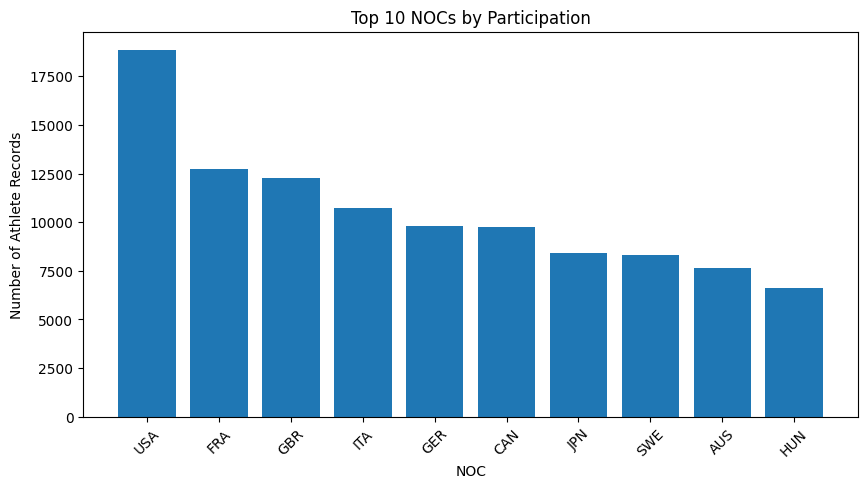

In [10]:
top_10_countries = country_participation.head(10)

plt.figure(figsize=(10, 5))

plt.bar(top_10_countries.index, top_10_countries.values)

plt.xlabel("NOC")
plt.ylabel("Number of Athlete Records")
plt.title("Top 10 NOCs by Participation")

plt.xticks(rotation=45)
plt.show()

## Sport-wise Olympic Participation

The `Sport` column contains the different sports in which athletes participated.

We will count the number of athlete records for each sport to understand which sports had higher participation.

In [11]:
sport_participation = data["Sport"].value_counts()

sport_participation.head(10)

,count
Sport,
Athletics,38624
Gymnastics,26707
Swimming,23195
Shooting,11448
Cycling,10859
Fencing,10735
Rowing,10595
Cross Country Skiing,9133
Alpine Skiing,8829


In [12]:
unique_athletes_sport = (
    data.groupby("Sport")["Name"]
    .nunique()
    .sort_values(ascending=False)
)

unique_athletes_sport.head(10)

,Name
Sport,
Athletics,22053
Swimming,8761
Rowing,7684
Football,6161
Cycling,5819
Boxing,5254
Wrestling,4987
Shooting,4879
Sailing,4480


## Visualizing Unique Athletes by Sport

A bar chart helps us compare the number of unique athletes across the most participated sports.

The chart shows the top 10 sports based on the number of different athletes.

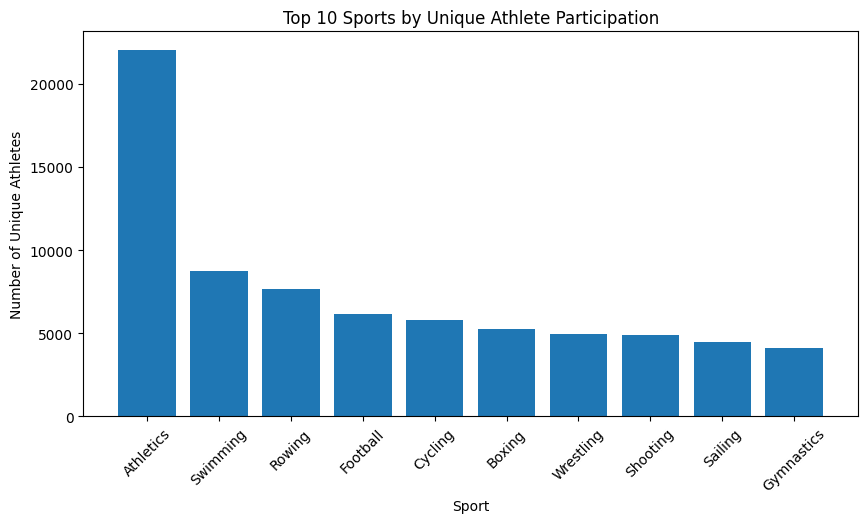

In [13]:
top_10_sports = unique_athletes_sport.head(10)

plt.figure(figsize=(10, 5))

plt.bar(top_10_sports.index, top_10_sports.values)

plt.xlabel("Sport")
plt.ylabel("Number of Unique Athletes")
plt.title("Top 10 Sports by Unique Athlete Participation")

plt.xticks(rotation=45)
plt.show()

## Summer vs Winter Olympic Participation

The Olympic Games are divided into two main seasons: Summer and Winter.

We will compare the number of athlete records in each season to understand the participation pattern across the two types of Olympic Games.

In [15]:
season_participation = data["Season"].value_counts()

season_participation

,count
Season,
Summer,222552
Winter,48564


## MEDAL ANALYSIS

In [16]:
medal_counts = data["Medal"].value_counts()

medal_counts

,count
Medal,
Gold,13372
Bronze,13295
Silver,13116


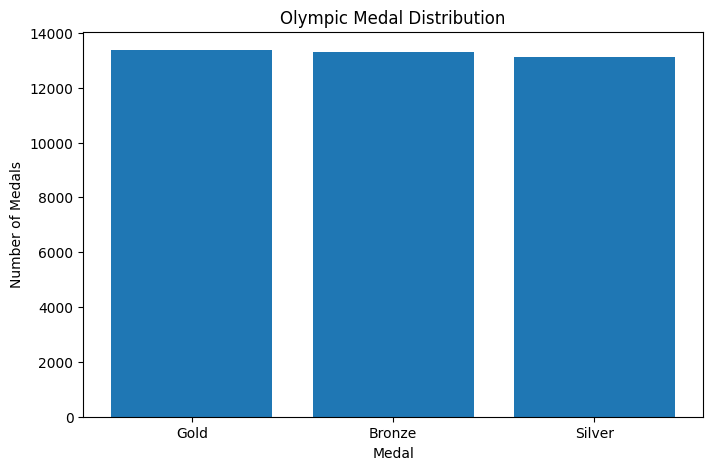

In [17]:
plt.figure(figsize=(8, 5))

plt.bar(medal_counts.index, medal_counts.values)

plt.xlabel("Medal")
plt.ylabel("Number of Medals")
plt.title("Olympic Medal Distribution")

plt.show()

## Country-wise Medal Analysis

We will identify the countries with the highest number of recorded medals.

The analysis focuses only on rows where a medal was recorded.

In [18]:
medal_data = data.dropna(subset=["Medal"])

country_medals = medal_data["NOC"].value_counts()

country_medals.head(10)

,count
NOC,
USA,5637
URS,2503
GER,2165
GBR,2068
FRA,1777
ITA,1637
SWE,1536
CAN,1352
AUS,1320


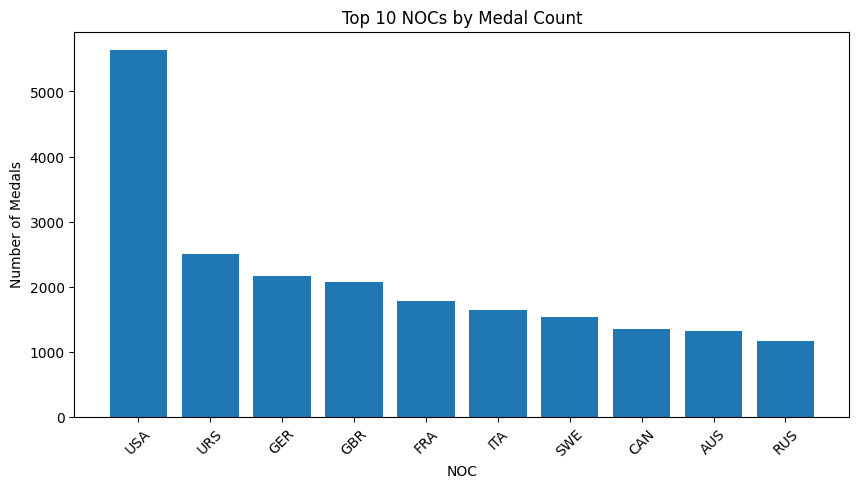

In [19]:
top_10_medal_countries = country_medals.head(10)

plt.figure(figsize=(10, 5))

plt.bar(top_10_medal_countries.index, top_10_medal_countries.values)

plt.xlabel("NOC")
plt.ylabel("Number of Medals")
plt.title("Top 10 NOCs by Medal Count")

plt.xticks(rotation=45)
plt.show()

## Country-wise Medal Type Analysis

Different medals can be analyzed separately to understand the distribution of Gold, Silver, and Bronze medals across countries.

We will count each medal type for every NOC.

In [20]:
medal_by_country = pd.crosstab(
    medal_data["NOC"],
    medal_data["Medal"]
)

medal_by_country.head()

Medal,Bronze,Gold,Silver
NOC,,,
AFG,2,0,0
AHO,0,0,1
ALG,8,5,4
ANZ,5,20,4
ARG,91,91,92


In [21]:
top_gold_countries = (
    medal_by_country["Gold"]
    .sort_values(ascending=False)
    .head(10)
)

top_gold_countries

,Gold
NOC,
USA,2638
URS,1082
GER,745
GBR,678
ITA,575
FRA,501
SWE,479
CAN,463
HUN,432


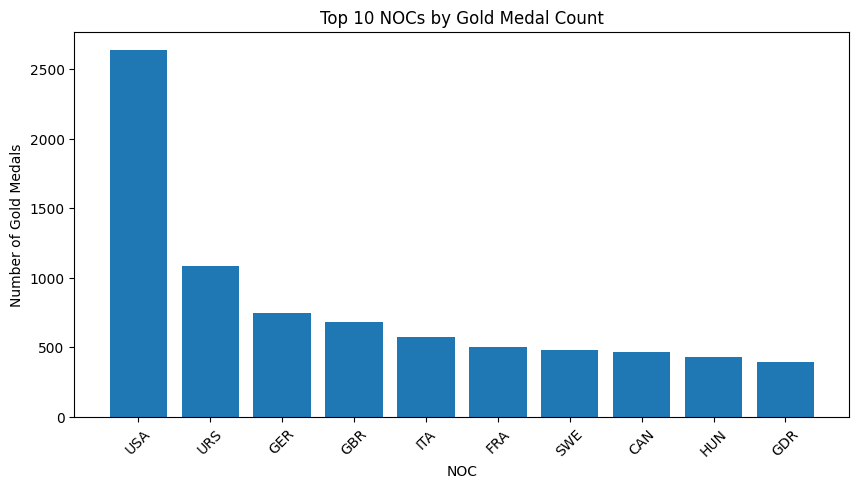

In [22]:
plt.figure(figsize=(10, 5))

plt.bar(top_gold_countries.index, top_gold_countries.values)

plt.xlabel("NOC")
plt.ylabel("Number of Gold Medals")
plt.title("Top 10 NOCs by Gold Medal Count")

plt.xticks(rotation=45)
plt.show()

## Athlete Age Analysis

Age is an important factor in understanding Olympic participation.

We will analyze the age distribution of athletes to understand the typical age range of participants.

In [23]:
age_data = data["Age"].dropna()

age_data.describe()

,Age
count,261642.000000
mean,25.556898
std,6.393561
min,10.000000
25%,21.000000
50%,24.000000
75%,28.000000
max,97.000000


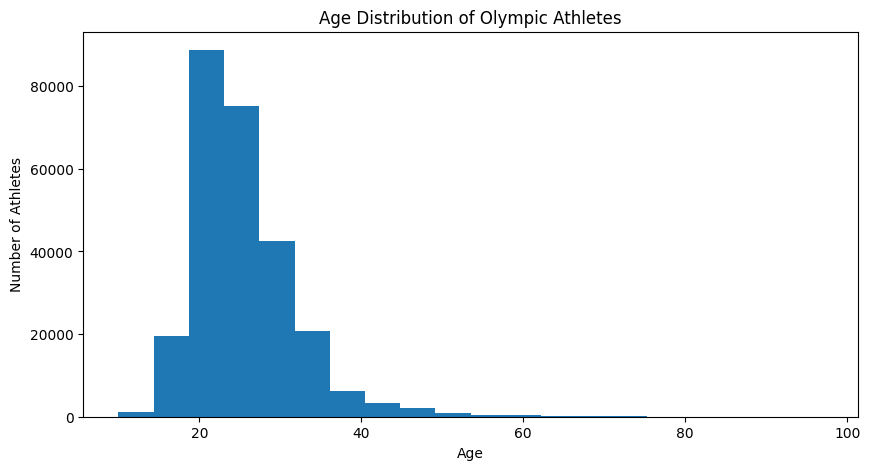

In [24]:
plt.figure(figsize=(10, 5))

plt.hist(age_data, bins=20)

plt.xlabel("Age")
plt.ylabel("Number of Athletes")
plt.title("Age Distribution of Olympic Athletes")

plt.show()

## Height and Weight Relationship

Height and weight are important physical characteristics of athletes.

We will compare height and weight to observe whether there is any visible relationship between these two variables.

In [25]:
height_weight = data[["Height", "Weight"]].dropna()

height_weight.head()

,Height,Weight
0,180.0,80.0
1,170.0,60.0
4,185.0,82.0
5,185.0,82.0
6,185.0,82.0


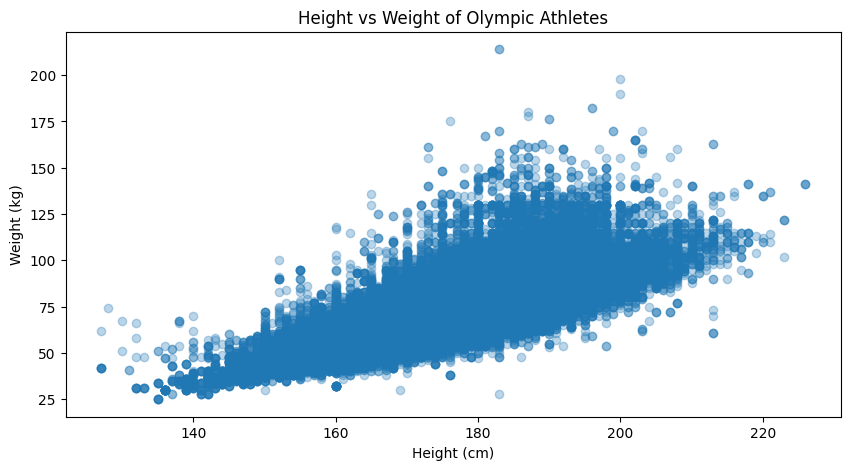

In [26]:
plt.figure(figsize=(10, 5))

plt.scatter(height_weight["Height"], height_weight["Weight"], alpha=0.3)

plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Height vs Weight of Olympic Athletes")

plt.show()

## Olympic Participation Over the Years

The dataset contains Olympic Games from different years.

We will count the number of athlete records for each Olympic year to observe how participation changed over time.

In [27]:
year_participation = data["Year"].value_counts().sort_index()

year_participation

,count
Year,
1896,380
1900,1936
1904,1301
1906,1733
1908,3101
1912,4040
1920,4292
1924,5693
1928,5574


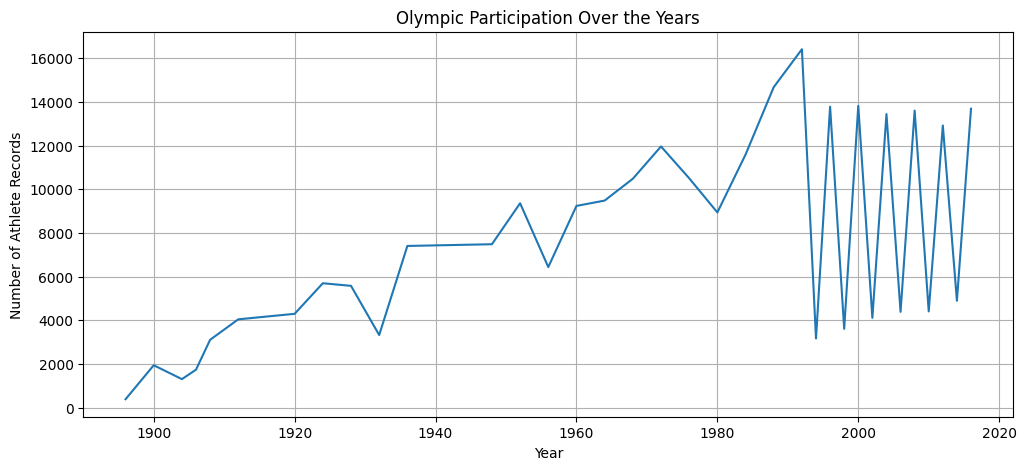

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(year_participation.index, year_participation.values)

plt.xlabel("Year")
plt.ylabel("Number of Athlete Records")
plt.title("Olympic Participation Over the Years")

plt.grid(True)
plt.show()

## Most Participated Olympic Events

The `Event` column represents the specific events in which athletes competed.

We will identify the events with the highest number of athlete records in the dataset.

In [29]:
event_participation = data["Event"].value_counts()

event_participation.head(10)

,count
Event,
Football Men's Football,5733
Ice Hockey Men's Ice Hockey,4762
Hockey Men's Hockey,3958
Water Polo Men's Water Polo,3358
Basketball Men's Basketball,3280
"Cycling Men's Road Race, Individual",2947
Gymnastics Men's Individual All-Around,2500
Rowing Men's Coxed Eights,2423
Gymnastics Men's Team All-Around,2411


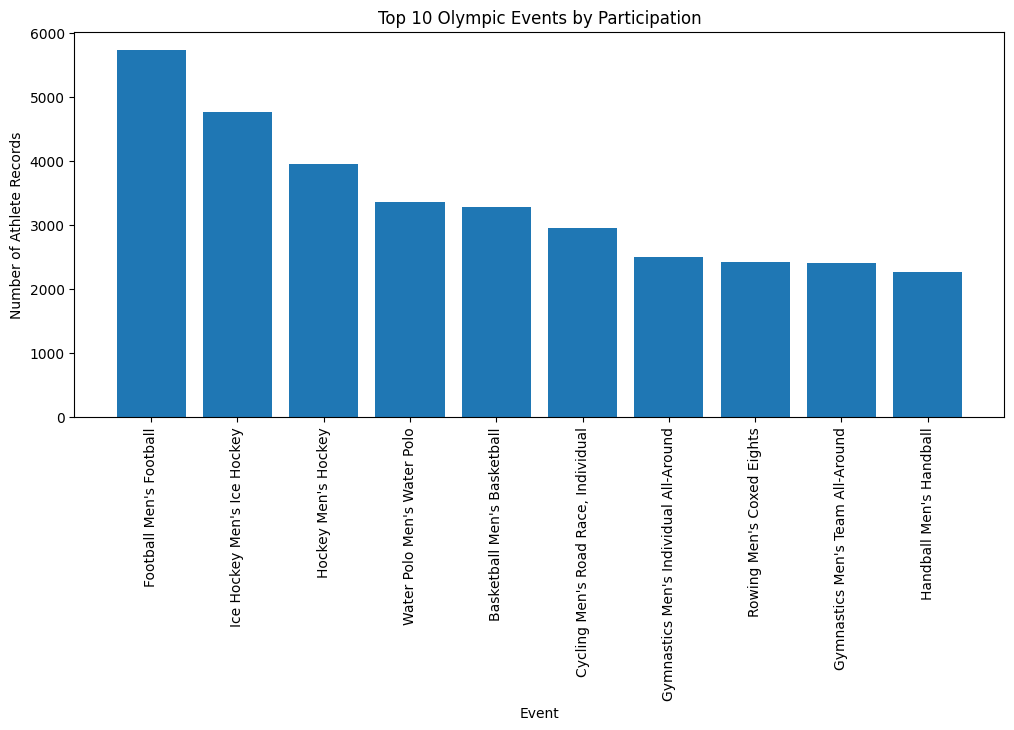

In [30]:
top_10_events = event_participation.head(10)

plt.figure(figsize=(12, 5))

plt.bar(top_10_events.index, top_10_events.values)

plt.xlabel("Event")
plt.ylabel("Number of Athlete Records")
plt.title("Top 10 Olympic Events by Participation")

plt.xticks(rotation=90)
plt.show()

## India's Olympic Medal Records

We will analyze India's recorded Olympic medals and find the total number of medal records along with the Gold, Silver, and Bronze medal counts.

In [31]:
india_medals = medal_data[medal_data["NOC"] == "IND"]

india_medal_counts = india_medals["Medal"].value_counts()

print("Total Medal Records:", len(india_medals))
print("\nMedal-wise Count:")
print(india_medal_counts)

Total Medal Records: 197

Medal-wise Count:
Medal
Gold      138
Bronze     40
Silver     19
Name: count, dtype: int64


## Key Findings

The Olympic Games dataset was analyzed to understand athlete participation, sports, medals, and physical characteristics.

The analysis showed that:

- Olympic participation varied across different years.
- Some NOCs had a higher number of athlete records than others.
- Sports differed in the number of unique athletes participating.
- Gold, Silver, and Bronze medals had different overall distributions.
- Some NOCs had a high number of recorded medals.
- Athlete ages covered a wide range, with some age groups having higher participation.
- Height and weight showed a visible relationship among athlete records.
- Different Olympic events had different levels of participation.
-India was also analyzed separately to understand its Olympic medal records. The analysis identified India's total recorded medal entries and their distribution across Gold, Silver, and Bronze medals. This provided a country-specific view within the overall Olympic dataset.

Overall, the analysis demonstrates how Pandas and data visualization can be used to explore a large real-world dataset and identify meaningful patterns.